# Can Money Buy Wins? Predicting MLB Win %
**DTSC 2302 Group 21:** Ryan Williams, Eshan Khandekar, Will Arboscello

**Research question:** Does a metro area's real GDP per capita improve predictions of an MLB team's
season win % beyond what payroll and population already explain?

| Model | What we examine |
|---|---|
| Ridge Regression | Coefficients: how GDP, payroll, and population relate to win % |
| Random Forest | Feature importance: which predictors are most useful |
| Gradient Boosting | Accuracy: does adding each variable improve predictions? |

**Data** (in the `data/` folder):
- `teams.csv`, `salaries.csv`: Lahman Baseball Database (SABR), 2001–2016
- `metro_gdp.csv`: real GDP and GDP per capita by metro area from FRED (original source: BEA). Downloaded automatically the first time you run Step 2.

Run the cells in order, top to bottom.

In [1]:
# Setup: libraries and settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42      # same results every run
GAMES = 162    # converts win % into wins (0.05 x 162 = about 8 wins)
pd.options.display.float_format = "{:.3f}".format
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})

## Step 1: Team data (wins and payroll)
One row = one team in one season.

In [2]:
teams = pd.read_csv("data/teams.csv")
salaries = pd.read_csv("data/salaries.csv")

# Target: win % = wins / games played
teams["win_pct"] = teams["W"] / (teams["W"] + teams["L"])

# Last season's win % (matched by franchise, since some teams changed names/IDs)
teams = teams.sort_values(["franchID", "yearID"])
teams["prev_win_pct"] = teams.groupby("franchID")["win_pct"].shift(1)

# Payroll = sum of player salaries. Relative payroll = payroll / league average that year
# (1.5 = 50% more than the average team), so dollars compare fairly across years.
payroll = salaries.groupby(["yearID", "teamID"])["salary"].sum().rename("payroll").reset_index()
payroll["rel_payroll"] = payroll["payroll"] / payroll.groupby("yearID")["payroll"].transform("mean")
teams = teams.merge(payroll, on=["yearID", "teamID"])

teams.head()

,yearID,teamID,franchID,name,W,L,win_pct,prev_win_pct,payroll,rel_payroll
0,2001,ANA,ANA,Anaheim Angels,75,87,0.463,NaN,47535167,0.727
1,2002,ANA,ANA,Anaheim Angels,99,63,0.611,0.463,61721667,0.915
2,2003,ANA,ANA,Anaheim Angels,77,85,0.475,0.611,79031667,1.114
3,2004,ANA,ANA,Anaheim Angels,92,70,0.568,0.475,100534667,1.457
4,2005,LAA,ANA,Los Angeles Angels of Anaheim,95,67,0.586,0.568,94867822,1.300


## Step 2: Metro GDP and population (FRED)
Each team is matched to its metro area code. For each metro we use two FRED series:
`RGMP` (real GDP) and `PCRGMP` (real GDP per person). Population = GDP ÷ GDP per person.
The first run downloads them and saves `data/metro_gdp.csv`; after that the CSV is used.

In [3]:
# Metro area code for each team (Toronto and Montreal are in Canada: no U.S. GDP, so excluded)
METRO = {
    "NYA": 35620, "NYN": 35620, "LAN": 31080, "LAA": 31080, "ANA": 31080,
    "CHA": 16980, "CHN": 16980, "SFN": 41860, "OAK": 41860, "BOS": 14460,
    "PHI": 37980, "WAS": 47900, "BAL": 12580, "ATL": 12060, "FLO": 33100,
    "MIA": 33100, "TBA": 45300, "PIT": 38300, "CLE": 17460, "CIN": 17140,
    "DET": 19820, "MIL": 33340, "MIN": 33460, "SLN": 41180, "KCA": 28140,
    "HOU": 26420, "TEX": 19100, "COL": 19740, "ARI": 38060, "SDN": 41740, "SEA": 42660,
}

def fred(series_id):
    """Download one FRED series (no API key needed) as columns: year, value."""
    df = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}")
    df.columns = ["date", "value"]
    return pd.DataFrame({"year": pd.to_datetime(df["date"]).dt.year,
                         "value": pd.to_numeric(df["value"], errors="coerce")})

try:
    gdp = pd.read_csv("data/metro_gdp.csv")          # use the saved file if we have it
except FileNotFoundError:
    rows = []
    for code in sorted(set(METRO.values())):
        for c in (code, 17410) if code == 17460 else (code,):   # Cleveland's code changed to 17410
            try:
                g = fred(f"RGMP{c}").rename(columns={"value": "real_gdp_millions"})
                g = g.merge(fred(f"PCRGMP{c}").rename(columns={"value": "gdp_per_capita"}), on="year")
                rows.append(g.assign(metro=code))
                break
            except Exception as e:
                print(f"Could not download metro {c}: {e}")
    gdp = pd.concat(rows)
    gdp["population"] = gdp["real_gdp_millions"] * 1e6 / gdp["gdp_per_capita"]
    gdp.to_csv("data/metro_gdp.csv", index=False)

gdp.head()

,year,real_gdp_millions,gdp_per_capita,metro,population
0,2001,271180.503,57356,12060,4728023.276
1,2002,273930.846,56424,12060,4854863.994
2,2003,282151.814,56316,12060,5010153.669
3,2004,298232.221,56654,12060,5264098.228
4,2005,313144.329,57647,12060,5432101.046


## Step 3: Build the final dataset
We use **last year's** GDP and population for each season, because a forecast made before the
season could only know last year's economy (this prevents data leakage).

In [4]:
teams["metro"] = teams["teamID"].map(METRO)
gdp_last_year = gdp.assign(yearID=gdp["year"] + 1)[["metro", "yearID", "gdp_per_capita", "population"]]
data = teams.merge(gdp_last_year, on=["metro", "yearID"])     # also drops Toronto and Montreal

# Log scale so a few huge metros (like New York) don't dominate
data["log_population"] = np.log(data["population"])
data["log_gdp_per_capita"] = np.log(data["gdp_per_capita"])

FEATURES = ["prev_win_pct", "rel_payroll", "log_population", "log_gdp_per_capita"]
data = data[data["yearID"].between(2002, 2016)].dropna(subset=FEATURES + ["win_pct"])
data.to_csv("data/team_seasons.csv", index=False)
print(f"{len(data)} team-seasons, {data['yearID'].min()}-{data['yearID'].max()}")
data[["win_pct"] + FEATURES].describe()

432 team-seasons, 2002-2016


,win_pct,prev_win_pct,rel_payroll,log_population,log_gdp_per_capita
count,432.000,432.000,432.000,432.000,432.000
mean,0.500,0.500,1.006,15.433,10.953
std,0.071,0.072,0.412,0.669,0.162
min,0.265,0.265,0.177,14.299,10.554
25%,0.444,0.444,0.723,14.932,10.838
50%,0.500,0.505,0.933,15.381,10.955
75%,0.556,0.556,1.216,15.720,11.046
max,0.648,0.716,2.855,16.974,11.333


## Step 4: Train/test split and baselines
We **train on 2002–2012** and **test on 2013–2016**, like a real forecast. (A random split would
let models peek at a team's future seasons.) Every model must beat two simple guesses.

**Metrics:** MAE = average miss · RMSE = punishes big misses more · R² = share of differences explained (1 = perfect)

In [5]:
train, test = data[data["yearID"] <= 2012], data[data["yearID"] >= 2013]
X_train, y_train = train[FEATURES], train["win_pct"]
X_test, y_test = test[FEATURES], test["win_pct"]
print(f"Train: {len(train)} rows | Test: {len(test)} rows")

def score(name, pred):
    """Accuracy of predictions on the test seasons."""
    mae = mean_absolute_error(y_test, pred)
    return {"model": name, "MAE": mae, "MAE (wins)": mae * GAMES,
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)), "R2": r2_score(y_test, pred)}

results = [score("Baseline: every team .500", np.full(len(test), 0.5)),
           score("Baseline: repeat last season", test["prev_win_pct"])]
pd.DataFrame(results)

Train: 316 rows | Test: 116 rows


,model,MAE,MAE (wins),RMSE,R2
0,Baseline: every team .500,0.056,9.097,0.066,-0.000
1,Baseline: repeat last season,0.057,9.311,0.070,-0.131


## Model 1: Ridge Regression → coefficients
Ridge fits a straight-line relationship for each feature and shrinks coefficients so no feature
takes over. Features are standardized, so each coefficient = **change in wins for a one standard
deviation increase**, holding the others fixed. Positive = more of it → more wins.

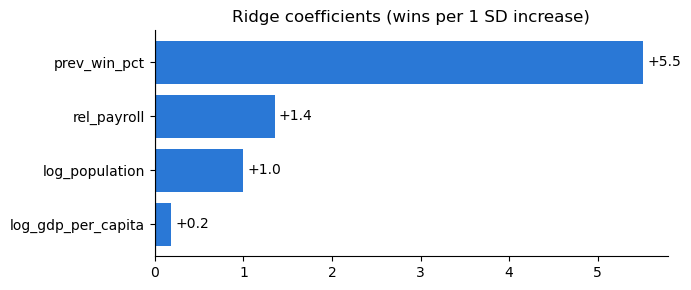

,wins per 1 SD
log_gdp_per_capita,0.186
log_population,1.000
rel_payroll,1.353
prev_win_pct,5.515


In [6]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train, y_train)
results.append(score("Ridge Regression", ridge.predict(X_test)))

coefs = pd.Series(ridge[-1].coef_ * GAMES, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar_label(ax.barh(coefs.index, coefs, color=["#eb6834" if v < 0 else "#2a78d6" for v in coefs]), fmt="%+.1f", padding=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Ridge coefficients (wins per 1 SD increase)")
plt.tight_layout(); plt.savefig("ridge_coefficients.png"); plt.show()
coefs.rename("wins per 1 SD").to_frame()

## Model 2: Random Forest → feature importance
A random forest averages 500 decision trees, each asking yes/no questions ("is payroll above
1.2?"). Trees can catch curved patterns, like extra money helping less and less.
**Feature importance** = each feature's share of how much the trees reduced error (adds to 100%).

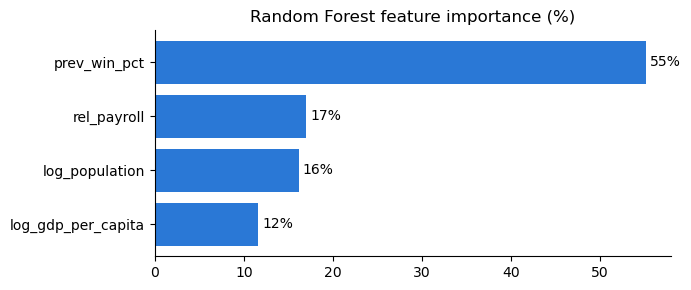

,importance %
log_gdp_per_capita,11.630
log_population,16.150
rel_payroll,17.027
prev_win_pct,55.194


In [7]:
forest = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=SEED).fit(X_train, y_train)
results.append(score("Random Forest", forest.predict(X_test)))

importance = pd.Series(forest.feature_importances_ * 100, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar_label(ax.barh(importance.index, importance, color="#2a78d6"), fmt="%.0f%%", padding=3)
ax.set_title("Random Forest feature importance (%)")
plt.tight_layout(); plt.savefig("forest_importance.png"); plt.show()
importance.rename("importance %").to_frame()

## Model 3: Gradient Boosting → do new variables improve predictions?
Gradient boosting builds small trees one at a time, each fixing the last ones' mistakes.
We add one variable at a time: **Payroll → + Population → + GDP per capita.**
If the average miss goes **down** when GDP is added, GDP improves predictions.

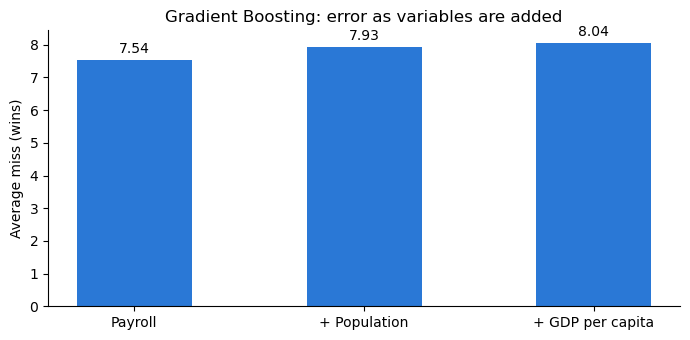

Adding GDP per capita changed the average miss by +0.11 wins (negative = GDP helped).


,MAE,MAE (wins),RMSE,R2,change (wins)
model,,,,,
Payroll,0.047,7.541,0.058,0.229,NaN
+ Population,0.049,7.926,0.060,0.167,0.386
+ GDP per capita,0.050,8.039,0.061,0.153,0.112


In [8]:
feature_sets = {
    "Payroll":          ["prev_win_pct", "rel_payroll"],
    "+ Population":     ["prev_win_pct", "rel_payroll", "log_population"],
    "+ GDP per capita": FEATURES,
}
steps = []
for name, cols in feature_sets.items():
    boost = GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=2,
                                      subsample=0.8, random_state=SEED).fit(train[cols], y_train)
    steps.append(score(name, boost.predict(test[cols])))
results.append(score("Gradient Boosting", boost.predict(X_test)))   # last model uses all features

steps = pd.DataFrame(steps).set_index("model")
steps["change (wins)"] = steps["MAE (wins)"].diff()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar_label(ax.bar(steps.index, steps["MAE (wins)"], color="#2a78d6", width=0.5), fmt="%.2f", padding=3)
ax.set(ylabel="Average miss (wins)", title="Gradient Boosting: error as variables are added")
plt.tight_layout(); plt.savefig("boosting_feature_sets.png"); plt.show()

print(f"Adding GDP per capita changed the average miss by {steps['change (wins)'].iloc[-1]:+.2f} wins "
      "(negative = GDP helped).")
steps

## Compare all three models

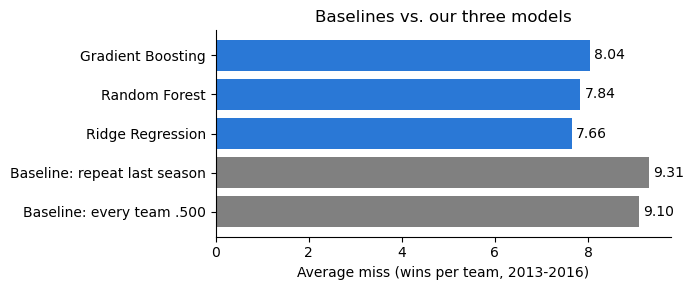

,MAE,MAE (wins),RMSE,R2
model,,,,
Baseline: every team .500,0.056,9.097,0.066,-0.000
Baseline: repeat last season,0.057,9.311,0.070,-0.131
Ridge Regression,0.047,7.655,0.058,0.223
Random Forest,0.048,7.837,0.060,0.179
Gradient Boosting,0.050,8.039,0.061,0.153


In [9]:
comparison = pd.DataFrame(results).set_index("model")
comparison.to_csv("data/model_results.csv")

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(comparison.index, comparison["MAE (wins)"], color=["gray"] * 2 + ["#2a78d6"] * 3)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(xlabel="Average miss (wins per team, 2013-2016)", title="Baselines vs. our three models")
plt.tight_layout(); plt.savefig("model_comparison.png"); plt.show()
comparison

**Reminder for the report:** these models measure *prediction, not causation*. Even if GDP improves
predictions, that doesn't prove a richer city causes more wins (Hall et al., 2002). Front-office skill,
injuries, and luck aren't in our data. NY, LA, Chicago, and SF-Oakland each have two teams sharing one GDP.